# Football Injury Burden — Reproducible Public Review

**Víctor Andrés Gómez López · 2026**

An independent aggregate analysis of recorded football absences. The original data were created by **Sanan Muzaffarov**, [European Football Injuries (2020–2025), Kaggle version 2](https://www.kaggle.com/datasets/sananmuzaffarov/european-football-injuries-2020-2025/versions/2), listed as **CC BY-SA 4.0**. Derived data and figures retain that license; original notebook code/prose is MIT. Transformations: explicit date/duration parsing, record-quality audit, raw-label aggregation and candidate same-interval sensitivity. See the bundled data-license notice.

This review loads **derived aggregate statistics**, not the original raw CSV or individual medical histories. It does not estimate true injury incidence, availability percentages, clinical recovery prognosis or prospective injury risk. No independent medical-source verification has been completed.

[Interactive bilingual study](https://european-football-injuries.vercel.app) · [GitHub and full event-level reproduction](https://github.com/victorgomezadapty/european-football-injuries) · [Scientific discussion](https://european-football-injuries.vercel.app/evidence)


In [1]:
from pathlib import Path
import json
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

local = Path.cwd() / 'publication' / 'kaggle'
if (local / 'injury_burden.csv').exists():
    bundle = local
else:
    matches = list(Path('/kaggle/input').rglob('project_aggregate_views.json'))
    if len(matches) != 1:
        raise FileNotFoundError('Attach only the European Football Injuries Burden Analysis derivative dataset.')
    bundle = matches[0].parent

project = json.loads((bundle / 'project_aggregate_views.json').read_text(encoding='utf-8'))
injury = pd.read_csv(bundle / 'injury_burden.csv')
sensitivity = pd.read_csv(bundle / 'duplicate_sensitivity.csv')
manifest = json.loads((bundle / 'publication_manifest.json').read_text(encoding='utf-8'))
for item in manifest['files']:
    assert hashlib.sha256((bundle / item['name']).read_bytes()).hexdigest() == item['sha256'], item['name']
print('Aggregate release integrity checks passed.')
display(pd.DataFrame([{'original_records': project['summary']['raw_rows'],
                       'source_columns': project['summary']['raw_columns'],
                       'recorded_names': project['summary']['unique_recorded_player_names'],
                       'club_labels': project['summary']['clubs'],
                       'absence_labels': project['summary']['raw_injury_labels']}]))


Aggregate release integrity checks passed.


,original_records,source_columns,recorded_names,club_labels,absence_labels
0,15603,11,4081,145,276


## Reconcile the record-level summaries

Frequency, continuous reported duration and cumulative episode burden are distinct. The file includes illnesses, quarantine, fitness/rest and injuries. Summed days and matches can repeat across overlapping episodes or club contexts. The injury-label table retains its source wording.


In [2]:
assert int(injury.injury_count.sum()) == project['summary']['raw_rows']
assert injury.total_days_out.sum() == project['summary']['reported_total_days_out']
assert injury.total_games_missed.sum() == project['summary']['reported_total_games_missed']
display(injury.sort_values('injury_count', ascending=False).head(12))


,injury_type_raw,injury_count,unique_recorded_names,valid_days_count,median_days_out,mean_days_out,max_days_out,valid_games_count,median_games_missed,total_days_out,total_games_missed,p25_days_out,p75_days_out,p90_days_out,p95_days_out,iqr_days_out
0,Hamstring injury,1256,821,1256,29.0,41.785828,491.0,1256,5.0,52483.0,8534.0,18.0,51.00,86.0,117.50,33.00
1,Corona virus,986,853,986,12.0,14.007099,242.0,986,2.0,13811.0,2386.0,8.0,16.00,22.0,26.00,8.00
2,Muscle injury,960,677,960,25.0,31.962500,294.0,960,4.0,30684.0,5068.0,14.0,39.00,64.1,90.00,25.00
3,muscular problems,940,665,940,13.0,20.555319,360.0,940,2.0,19322.0,3060.0,8.0,23.25,43.0,60.00,15.25
4,Knee injury,584,458,584,36.0,63.844178,1013.0,584,6.0,37285.0,5441.0,18.0,72.00,136.0,223.85,54.00
5,Ill,578,447,578,7.0,9.354671,253.0,578,1.0,5407.0,974.0,4.0,9.00,15.0,22.00,5.00
6,Ankle injury,572,458,572,26.0,41.277972,362.0,572,4.0,23611.0,3628.0,13.0,53.00,93.9,127.00,40.00
7,Knock,441,350,441,12.0,18.693878,172.0,441,2.0,8244.0,1362.0,7.0,22.00,38.0,52.00,15.00
8,Calf injury,430,330,430,26.0,34.858140,272.0,430,4.0,14989.0,2487.0,16.0,40.00,67.0,90.00,24.00
9,Fitness,427,344,427,15.0,24.711944,295.0,427,2.0,10552.0,1531.0,8.0,27.50,57.4,83.70,19.50


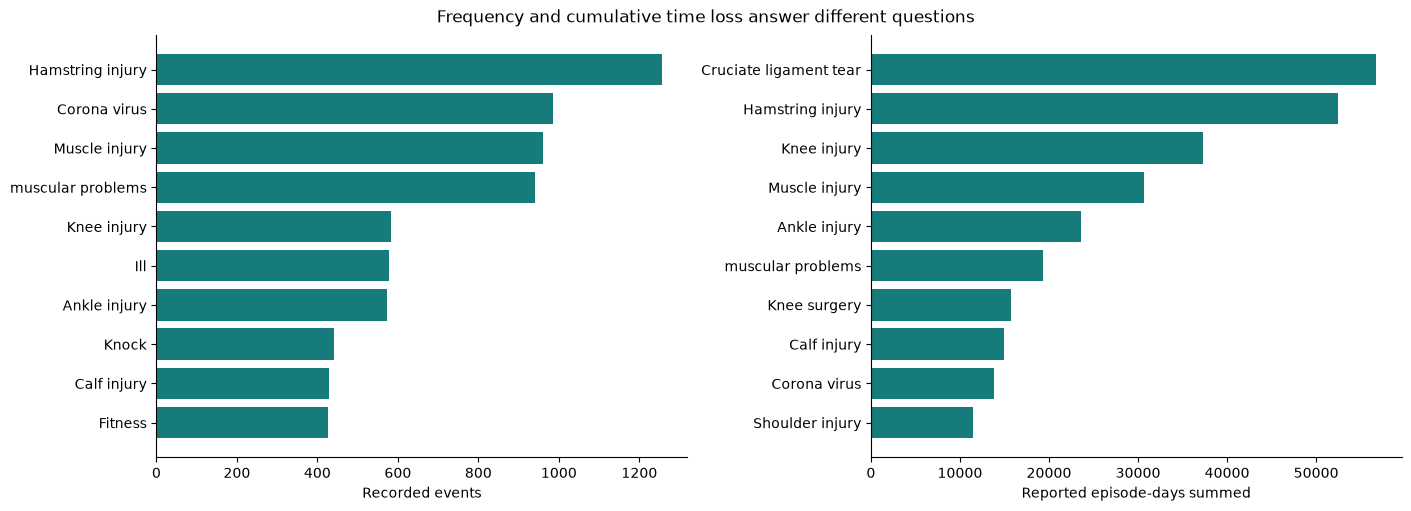

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')
for ax, metric, label in zip(axes, ['injury_count', 'total_days_out'], ['Recorded events', 'Reported episode-days summed']):
    selected = injury.nlargest(10, metric).iloc[::-1]
    ax.barh(selected.injury_type_raw, selected[metric], color='#177b7b')
    ax.set_xlabel(label)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Frequency and cumulative time loss answer different questions')
plt.show()


## Candidate repeated-interval sensitivity

The source has no exact whole-row duplicates, but **981 groups (1,973 rows)** repeat the same recorded name, normalized label and date interval across clubs. Within these groups, reported days and matches agree. Keeping the first source row per complete key yields **14,611 candidate rows**. This is a sensitivity assumption, not verification of clinical episode identity or club attribution.


In [4]:
display(sensitivity)
days_reduction = 100 * (1 - sensitivity.iloc[1].total_days_out / sensitivity.iloc[0].total_days_out)
print(f'Summed reported days change by {days_reduction:.2f}% under candidate collapsing.')


,cohort,record_count,total_days_out,total_games_missed,players_with_multiple_records,repeated_same_label_events
0,source_records_exact_deduplicated,15603,563314.0,85928.0,2795,2207
1,candidate_episode_collapsed_sensitivity,14611,532422.0,81226.0,2748,2062


Summed reported days change by 5.48% under candidate collapsing.


## Inspect a league/season combination

Change the selectors below to inspect exact precomputed subset summaries. Their medians come from the corresponding underlying records; medians are never averaged across groups. The candidate view keeps first-row context for sensitivity, so it is not an authoritative transfer or club attribution.


In [5]:
view = 'raw'  # 'raw' or 'candidate'
league = 'all'  # all, Bundesliga, La Liga, Ligue 1, Premier League, Serie A
season = 'all'  # all, 20/21, 21/22, 22/23, 23/24, 24/25
subset = project['views'][view][league + '|' + season]
subset_table = pd.DataFrame(subset['injuries'])
assert subset_table['count'].sum() == subset['count']
display(subset_table.sort_values('days', ascending=False).head(15))


,label,count,median,days,games,n,q1,q3
17,Cruciate ligament tear,226,230.5,56768,7533,226,192.25,281.00
0,Hamstring injury,1256,29.0,52483,8534,1256,18.00,51.00
4,Knee injury,584,36.0,37285,5441,584,18.00,72.00
2,Muscle injury,960,25.0,30684,5068,960,14.00,39.00
6,Ankle injury,572,26.0,23611,3628,572,13.00,53.00
3,muscular problems,940,13.0,19322,3060,940,8.00,23.25
35,Knee surgery,96,116.5,15702,2117,96,74.75,217.75
8,Calf injury,430,26.0,14989,2487,430,16.00,40.00
1,Corona virus,986,12.0,13811,2386,986,8.00,16.00
14,Shoulder injury,239,32.0,11411,1655,239,13.00,71.50


## Availability and incidence denominators are absent

Eligible fixtures, squad-registration and transfer intervals, complete observation windows and player match/training hours are missing. The first and last recorded injury dates are not valid observation denominators. A recorded end is not independently verified medical clearance. Gaps without records are not verified healthy time. No survival curve or prediction model is added to compensate for these missing definitions.

The public web therefore reports **Recorded Availability Burden Profiles** and aggregate consequences, without giving a player availability percentage. Repeated labels do not establish clinical reinjury.


# Discussion: recorded injury burden and player availability

This discussion connects the project's descriptive results with twelve selected publications. Published evidence supplies context and methodological standards; it does not medically validate the Kaggle archive. The [search record](literature_search.md) describes a targeted narrative search, not a systematic review. Reference numbers match the [reference registry](../references/references.json).

## 1. The observation unit determines the claim

The file contains 15,603 records, 4,081 recorded player names and 276 absence labels. Injury, illness, quarantine, fitness and rest appear together. The main count is therefore recorded absence-event frequency. The football consensus distinguishes injury definitions, recurrence, severity and exposure; its definitions cannot be assumed from a populated spreadsheet. [Fuller et al., 2006 [1]](https://doi.org/10.1136/bjsm.2005.025270)

The football-specific extension updates injury and illness recording and nomenclature. It supports retaining those distinctions, while leaving vague symptom labels unresolved instead of assigning a tissue diagnosis without evidence. The draft taxonomy is a review aid, not a clinically validated classification. [Waldén et al., 2023 [3]](https://doi.org/10.1136/bjsports-2022-106405)

## 2. Frequent absences and costly absences create different questions

**Hamstring injury** is the most frequent source label: 1,256 records, 52,483 summed reported episode-days and 8,534 summed missed matches. **Cruciate ligament tear** occurs in 226 records but accounts for 56,768 reported episode-days, with a median duration of 230.5 days. These are raw-label summaries, not verified diagnostic groups or individual prognoses.

The burden framework of Bahr and colleagues motivates showing consequence alongside frequency. The project's matrix applies that idea descriptively. Counts, duration and match loss reveal different planning questions; its frequency axis is not an incidence rate, and its median reference lines have no clinical threshold meaning. [Bahr et al., 2018 [4]](https://doi.org/10.1136/bjsports-2017-098160)

## 3. Hamstring prominence has relevant clinical context

The 21-season UEFA cohort used medical-staff injury records and individual exposure. It documented increasing hamstring injury and absence-day proportions. This supports the relevance of examining hamstring consequences, but does not make this archive's raw-label share equivalent to that cohort's clinical categories or exposure-based trends. [Ekstrand et al., 2023 [6]](https://doi.org/10.1136/bjsports-2021-105407)

Earlier prospective medical surveillance also identified substantial muscle-injury consequences and longer absences for clinically defined reinjuries. That supports retaining histories, while emphasizing why a repeated free-text label here cannot establish the same clinical outcome. [Ekstrand et al., 2011 [11]](https://doi.org/10.1177/0363546510395879)

The current data do not demonstrate an epidemic, a workload mechanism or a change in injury incidence.

## 4. Public visibility is selective

Validation by Krutsch and colleagues against team physicians found incorrect diagnoses and missing public/media injury records, with better agreement for some severe types. This shows that public visibility and diagnostic validity can vary by injury type; its results are not a universal correction factor for this file. [Krutsch et al., 2020 [7]](https://doi.org/10.2147/OAJSM.S251081)

Hoenig and colleagues found lower injury recording and a higher severe-injury proportion in a large Transfermarkt archive than in comparator sources. A large public dataset is therefore not necessarily representative. The present Kaggle version's upstream medical verification has not been established independently: this is a relevant analogy, not proof of identical errors. [Hoenig et al., 2022 [8]](https://doi.org/10.1016/j.jsams.2021.11.038)

Structured media surveillance can be useful: Aus der Fünten and colleagues used a defined prospective, multi-source protocol, while acknowledging difficulty identifying minor-injury diagnoses. Downloading an archive does not recreate such collection and exposure procedures. [Aus der Fünten et al., 2023 [9]](https://doi.org/10.1186/s40798-023-00563-x)

Zero missing cells means included records are populated; it does not establish that all injuries, eligible players or accurate diagnoses were captured.

## 5. Repeated intervals affect the headline totals

The primary record-level sum is **563,314 episode-days** and **85,928 missed matches**. No exact whole-row duplicates were found, but 1,973 rows share name surrogate, normalized label and dates with another row. Different club or other context prevents automatically declaring every matching interval a removable duplicate.

The candidate-collapsed sensitivity scenario retains 14,611 records, yielding 532,422 episode-days and 81,226 missed matches: reductions of approximately 5.48% and 5.47%. It keeps the first source row of each complete matching key; it does not adjudicate authoritative club attribution. Both views are published to expose that assumption.

The union of recorded inclusive date intervals avoids overlap double counting within a name, but does not establish complete absence history. Transfers, homonyms and competition-specific match losses still require verification.

## 6. Availability needs a denominator

Hägglund and colleagues observed associations between lower burden, higher match availability and better team performance in a prospectively monitored club cohort. This explains the relevance of availability analytics, without establishing causality or a team-performance effect in this archive. [Hägglund et al., 2013 [5]](https://doi.org/10.1136/bjsports-2013-092215)

Here, **Recorded Availability Burden Profiles** summarize documented consequences. A true availability proportion additionally needs eligible fixtures or observed eligible days, registration intervals and complete absence states. Incidence needs an appropriate exposure denominator. The IOC guidance explains why exposure and consequence measures must match the question; first-to-last-injury time is not a valid substitute. [Bahr et al., 2020 [2]](https://doi.org/10.1136/bjsports-2019-101969)

## 7. An end date is not medical clearance

Every reported duration equals the date difference plus one. Preserving this inclusive convention verifies arithmetic, not clinical endpoint meaning or equivalence to standardized surveillance time loss. Zero-day returns and full-participation definitions require the source protocol.

Return-to-sport guidance distinguishes progression through participation, sport and performance, with multifactorial shared decisions. A recorded interval end supplies none of those assessments. [Ardern et al., 2016 [10]](https://doi.org/10.1136/bjsports-2016-096278)

Repeated labels after recorded endpoints are therefore described as repeated recorded labels, not confirmed clinical reinjuries. Recovery modeling would first require endpoint and observation/censoring verification.

## 8. Calendar patterns generate questions

The monthly chart counts recorded onsets and assigns an episode's entire burden to its onset month. It does not distribute absence dates across months or isolate training-load effects.

A UEFA exposure-based subanalysis found no major overall incidence change during the 2022/23 World Cup season against its historical comparator, with setting-specific nuances. This illustrates why an unusual schedule does not establish its own causal conclusion; it does not show that congestion is harmless everywhere. [Bengtsson et al., 2025 [12]](https://doi.org/10.1136/bmjsem-2025-002772)

## 9. What this project contributes

The reproducible layer makes recorded absence composition, long durations, overlapping histories and sensitivity to repeated episodes explorable. It supports source review and resource-planning questions, not treatment selection, clinical clearance or future injury probabilities. Higher-value next work is identity and episode adjudication, taxonomy and endpoint validation, and complete registration, eligibility and exposure data. Any later onset model must exclude future-known outcomes and full-history totals.

Project-specific values come from `reports/dataset_summary.json` and the burden/sensitivity tables. The separately attributed source is Sanan Muzaffarov's Kaggle dataset. All external claims are linked to publications. No publisher figures, tables, abstracts or long quotations are reproduced.


## Reproduce from the original source

1. Clone the linked GitHub repository and install `requirements.txt`.
2. Download the official version 2 ZIP from the credited creator.
3. Run `python scripts/acquire_data.py --archive path/to/archive.zip`; the registered source checksum must match.
4. Run `python -m unittest discover -s tests -v`, then `python -m src.pipeline --as-of 2026-10-26`.
5. Rebuild detailed local notebooks with `python scripts/build_notebooks.py --execute`.

Raw and individual-history files are excluded from the public release. The public website can be rebuilt without the original raw CSV using `npm test` and `npm run build`. A fresh event-level recomputation intentionally requires obtaining the original source.

The accompanying `reproducible_source.zip`, methodology, search record, DOI bibliography and `DATA_LICENSE.md` describe the transformations and rights boundaries. This notebook's code license does not relicense source data or the scientific articles.
